# Yelp Restaurant Price Tier Prediction
**Goal:** Predict price tier ($, $$, $$$, $$$$) from Yelp Open Dataset features.

---

## 0. Paths & Imports

In [ ]:
import ast
import heapq
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

warnings.filterwarnings('ignore')

#Change path to your local
DATA_RAW   = Path("/Users/ericcarmi/Downloads/Big Data/DataFinalProject/Yelp JSON/yelp_dataset")  
DATA_PROC  = Path("/Users/ericcarmi/Downloads/Big Data/Final Project/data/processed")
DATA_PROC.mkdir(parents=True, exist_ok=True)

BIZ_JSON    = DATA_RAW / "yelp_academic_dataset_business.json"
REVIEW_JSON = DATA_RAW / "yelp_academic_dataset_review.json"

BIZ_PARQUET = DATA_PROC / "businesses_filtered.parquet"

# ── City filter ───────────────────────────────────────────────────────────────
# Set to None to use all cities (writes reviews_all.parquet).
# Set to a list to scope to specific cities (writes reviews_<city>.parquet).
# Each mode gets its own review cache so switching never reuses a stale file.
CITY_FILTER = ['Philadelphia']

def _review_parquet_path(city_filter):
    if city_filter is None:
        return DATA_PROC / "reviews_all.parquet"
    slug = '_'.join(c.strip().lower().replace(' ', '_') for c in sorted(city_filter))
    return DATA_PROC / f"reviews_{slug}.parquet"

REVIEW_PARQUET = _review_parquet_path(CITY_FILTER)

print("Raw data dir exists:", DATA_RAW.exists())
print("Business JSON:       ", BIZ_JSON.exists())
print("Review JSON:         ", REVIEW_JSON.exists())
print("City filter:         ", CITY_FILTER)
print("Review cache:        ", REVIEW_PARQUET.name)

Raw data dir exists: True
Business JSON:        True
Review JSON:          True
City filter:          ['Philadelphia']
Review cache:         reviews_philadelphia.parquet


---
## 1. Load & Clean

In [ ]:
def _safe_eval(val):
    """Parse a Yelp stringified Python literal; return None on failure."""
    if val is None or val == 'None':
        return None
    if isinstance(val, (bool, int, float)):
        return val
    if isinstance(val, str):
        v = val.strip()
        if v == 'True':  return True
        if v == 'False': return False
        try:
            return ast.literal_eval(v)
        except Exception:
            return v
    return val


def _flatten_attributes(attrs: dict) -> dict:
    """
    Parse all attribute values with _safe_eval and flatten dict-valued keys
    (Ambience, GoodForMeal, BusinessParking) into prefixed columns.
    """
    if not attrs:
        return {}
    flat = {}
    dict_keys = {'Ambience', 'GoodForMeal', 'BusinessParking'}
    for k, v in attrs.items():
        parsed = _safe_eval(v)
        if k in dict_keys and isinstance(parsed, dict):
            for sub_k, sub_v in parsed.items():
                flat[f"{k}_{sub_k}"] = _safe_eval(sub_v)
        else:
            flat[k] = parsed
    return flat

print("Helper functions defined.")

Helper functions defined.


In [ ]:
def load_businesses(raw_path: Path, cities=None) -> pd.DataFrame:
    """
    Stream yelp_academic_dataset_business.json and return a DataFrame of
    restaurants with a known price tier (1-4). Results cached to
    BIZ_PARQUET so raw JSON is only streamed once.

    Parameters
    ----------
    raw_path : Path  -- path to business JSONL file
    cities   : list[str] | None -- optional city filter (case-insensitive)

    If any requested city has < 500 restaurants, prints a city table and
    raises ValueError.
    """
    if BIZ_PARQUET.exists():
        print(f"[cache] Loading businesses from {BIZ_PARQUET}")
        df = pd.read_parquet(BIZ_PARQUET)
        if cities is not None:
            cities_norm = {c.strip().lower() for c in cities}
            df = df[df['city'].str.lower().isin(cities_norm)].reset_index(drop=True)
        return df

    if not raw_path.exists():
        raise FileNotFoundError(f"Business JSON not found: {raw_path}")

    records = []
    try:
        with open(raw_path, 'r', encoding='utf-8') as fh:
            pbar = tqdm(fh, desc="Streaming business.json", unit=" lines",
                        mininterval=1.0)
            for line in pbar:
                line = line.strip()
                if not line:
                    continue
                try:
                    biz = json.loads(line)
                except json.JSONDecodeError:
                    continue

                cats_raw  = biz.get('categories') or ''
                cats_list = [c.strip() for c in cats_raw.split(',') if c.strip()]
                if 'Restaurants' not in cats_list:
                    continue

                attrs     = biz.get('attributes') or {}
                price_raw = attrs.get('RestaurantsPriceRange2')
                try:
                    price_tier = int(float(str(_safe_eval(price_raw))))
                except (TypeError, ValueError):
                    continue
                if price_tier not in (1, 2, 3, 4):
                    continue

                city = (biz.get('city') or '').strip()
                flat_attrs = _flatten_attributes(attrs)
                flat_attrs.pop('RestaurantsPriceRange2', None)

                row = {
                    'business_id':  biz.get('business_id'),
                    'name':         biz.get('name'),
                    'city':         city,
                    'state':        biz.get('state'),
                    'latitude':     biz.get('latitude'),
                    'longitude':    biz.get('longitude'),
                    'review_count': biz.get('review_count'),
                    'stars':        biz.get('stars'),
                    'is_open':      biz.get('is_open'),
                    'categories':   cats_list,
                    'price_tier':   price_tier,
                    **flat_attrs,
                }
                records.append(row)
            pbar.close()
    except Exception as e:
        raise RuntimeError(f"Error reading {raw_path}: {e}") from e

    df_all = pd.DataFrame(records)
    df_all.to_parquet(BIZ_PARQUET, index=False)
    print(f"Saved {len(df_all):,} restaurant businesses to {BIZ_PARQUET}")

    if cities is None:
        return df_all

    cities_norm = {c.strip().lower() for c in cities}
    df = df_all[df_all['city'].str.lower().isin(cities_norm)].reset_index(drop=True)

    for city_req in cities_norm:
        n = (df['city'].str.lower() == city_req).sum()
        if n < 500:
            city_counts = (
                df_all.groupby('city').size()
                .sort_values(ascending=False)
                .rename('restaurant_count')
                .reset_index()
            )
            print(f"\nWARNING: '{city_req}' has only {n} restaurants (< 500 threshold).")
            print("\nAll available cities:")
            print(city_counts.to_string(index=False))
            raise ValueError(
                f"City '{city_req}' has too few restaurants ({n}). "
                "Choose a city from the table above."
            )
    return df

print("load_businesses defined.")

load_businesses defined.


In [ ]:
def load_reviews_for_businesses(
    raw_path: Path,
    business_ids: set,
    per_business: int = 40,
) -> pd.DataFrame:
    """
    Stream yelp_academic_dataset_review.json and return up to `per_business`
    reviews per business: the 20 most-recent and the 20 most-useful.
    Memory stays bounded via a per-business min-heap.
    Results cached to REVIEW_PARQUET.

    Parameters
    ----------
    raw_path     : Path -- path to review JSONL file
    business_ids : set  -- business_id strings to keep
    per_business : int  -- max reviews per business (split 50/50 recent vs useful)
    """
    if REVIEW_PARQUET.exists():
        print(f"[cache] Loading reviews from {REVIEW_PARQUET}")
        return pd.read_parquet(REVIEW_PARQUET)

    if not raw_path.exists():
        raise FileNotFoundError(f"Review JSON not found: {raw_path}")

    half = per_business // 2
    recent_heaps: dict = {}
    useful_heaps: dict = {}

    try:
        with open(raw_path, 'r', encoding='utf-8') as fh:
            pbar = tqdm(fh, desc="Streaming review.json", unit=" lines",
                        mininterval=2.0)
            for line in pbar:
                line = line.strip()
                if not line:
                    continue
                try:
                    rev = json.loads(line)
                except json.JSONDecodeError:
                    continue

                bid = rev.get('business_id')
                if bid not in business_ids:
                    continue

                record = (
                    bid,
                    rev.get('review_id'),
                    rev.get('user_id'),
                    rev.get('stars'),
                    rev.get('date', ''),
                    rev.get('text', ''),
                    rev.get('useful', 0),
                    rev.get('funny',  0),
                    rev.get('cool',   0),
                )
                date_key   = rev.get('date', '')
                useful_key = rev.get('useful', 0)

                heap_r = recent_heaps.setdefault(bid, [])
                if len(heap_r) < half:
                    heapq.heappush(heap_r, (date_key, record))
                elif date_key > heap_r[0][0]:
                    heapq.heapreplace(heap_r, (date_key, record))

                heap_u = useful_heaps.setdefault(bid, [])
                if len(heap_u) < half:
                    heapq.heappush(heap_u, (useful_key, record))
                elif useful_key > heap_u[0][0]:
                    heapq.heapreplace(heap_u, (useful_key, record))
            pbar.close()
    except Exception as e:
        raise RuntimeError(f"Error reading {raw_path}: {e}") from e

    COLS = ['business_id', 'review_id', 'user_id', 'stars',
            'date', 'text', 'useful', 'funny', 'cool']
    seen = {}
    for bid in business_ids:
        for _, rec in recent_heaps.get(bid, []):
            seen[rec[1]] = rec
        for _, rec in useful_heaps.get(bid, []):
            seen[rec[1]] = rec

    df = pd.DataFrame(list(seen.values()), columns=COLS)
    df.to_parquet(REVIEW_PARQUET, index=False)
    print(f"Saved {len(df):,} reviews to {REVIEW_PARQUET}")
    return df

print("load_reviews_for_businesses defined.")

load_reviews_for_businesses defined.


In [ ]:
# ── RUN SECTION 1 ─────────────────────────────────────────────────────────────
# Step A: run with CITY_FILTER = None to see all available cities.
# Step B: set CITY_FILTER to your chosen city (e.g. ['Philadelphia']) and re-run.

CITY_FILTER = None   # <- change after seeing city table

biz_df = load_businesses(BIZ_JSON, cities=CITY_FILTER)

if CITY_FILTER is None:
    city_counts = (
        biz_df.groupby('city').size()
        .sort_values(ascending=False)
        .rename('restaurant_count')
        .reset_index()
        .head(40)
    )
    print("\nTop 40 cities by restaurant count (all metros in dataset):")
    print(city_counts.to_string(index=False))

[cache] Loading businesses from /Users/ericcarmi/Downloads/Big Data/Final Project/data/processed/businesses_filtered.parquet

Top 40 cities by restaurant count (all metros in dataset):
            city  restaurant_count
    Philadelphia              4939
    Indianapolis              2505
           Tampa              2441
          Tucson              2167
       Nashville              2074
     New Orleans              1945
        Edmonton              1718
     Saint Louis              1705
            Reno              1169
           Boise               734
   Santa Barbara               689
      Clearwater               576
      Wilmington               521
        Metairie               479
Saint Petersburg               437
        Franklin               381
       St. Louis               375
  St. Petersburg               323
          Sparks               301
         Brandon               280
     Cherry Hill               266
           Largo               264
        Me

In [ ]:
# ── Load reviews (run after confirming biz_df) ────────────────────────────────
bid_set   = set(biz_df['business_id'])
review_df = load_reviews_for_businesses(REVIEW_JSON, bid_set, per_business=40)

print(f"\nBusinesses kept : {len(biz_df):,}")
print(f"Reviews kept    : {len(review_df):,}")
print("\nPrice-tier distribution:")
pt = biz_df['price_tier'].value_counts().sort_index()
for tier, cnt in pt.items():
    print(f"  {'$'*tier:5s} ({tier})  {cnt:6,}  ({cnt/len(biz_df)*100:.1f}%)")

[cache] Loading reviews from /Users/ericcarmi/Downloads/Big Data/Final Project/data/processed/reviews_philadelphia.parquet

Businesses kept : 44,484
Reviews kept    : 140,363

Price-tier distribution:
  $     (1)  19,509  (43.9%)
  $$    (2)  23,119  (52.0%)
  $$$   (3)   1,662  (3.7%)
  $$$$  (4)     194  (0.4%)


---
## 2. Features


In [ ]:
from collections import Counter

def build_feature_table(businesses_df: pd.DataFrame,
                        reviews_df: pd.DataFrame):
    """
    Build feature matrix X and target y, one row per business_id.

    Features
    --------
    - Numeric: review_count (log1p), stars, is_open, latitude, longitude
    - Top-30 sub-category dummies (excl. Restaurants, Food)
    - Attribute columns: bool attrs as 0/1, string attrs one-hotted
    - Ambience_* and GoodForMeal_* flattened booleans
    - Review aggregates: rv_count, rv_stars_mean, rv_stars_std,
      rv_len_chars_mean, rv_len_words_mean, rv_useful_mean

    Returns
    -------
    X : pd.DataFrame
    y : pd.Series
    """
    df = businesses_df.copy().set_index('business_id')
    y  = df['price_tier'].astype(int)

    # 1. core numerics
    df['review_count_log'] = np.log1p(df['review_count'].fillna(0))
    X = df[['review_count_log', 'stars', 'is_open',
             'latitude', 'longitude']].copy()

    # 2. top-30 category dummies
    skip = {'Restaurants', 'Food'}
    all_cats = Counter()
    for cats in df['categories']:
        if isinstance(cats, list):
            all_cats.update(c for c in cats if c not in skip)
    top30 = [c for c, _ in all_cats.most_common(30)]
    for cat in top30:
        col = 'cat_' + cat.replace(' ', '_').replace('&', 'and').replace('/', '_')
        X[col] = df['categories'].apply(
            lambda lst, c=cat: int(c in lst) if isinstance(lst, list) else 0
        )

    # 3a. bool attribute columns
    bool_attrs = [
        'RestaurantsTakeOut', 'RestaurantsReservations', 'RestaurantsDelivery',
        'GoodForKids', 'OutdoorSeating', 'HasTV', 'BikeParking',
        'BusinessAcceptsCreditCards', 'Caters', 'DogsAllowed',
    ]
    for col in bool_attrs:
        if col in df.columns:
            X[col] = df[col].apply(lambda v: 1 if v is True else 0)

    # 3b. flattened Ambience / GoodForMeal booleans
    for col in df.columns:
        if col.startswith(('Ambience_', 'GoodForMeal_')):
            X[col] = df[col].apply(lambda v: 1 if v is True else 0)

    # 3c. string attributes -> one-hot
    for col in ['Alcohol', 'WiFi', 'NoiseLevel', 'RestaurantsAttire']:
        if col in df.columns:
            s = df[col].apply(
                lambda v: str(v).strip().strip("'\"" ).lower()
                          if v is not None and str(v) not in ('None', 'nan', '') else None
            )
            dummies = pd.get_dummies(s, prefix=col, dtype=int)
            X = pd.concat([X, dummies], axis=1)

    # 4. review aggregates
    if len(reviews_df) > 0:
        rev = reviews_df.copy()
        rev['text_len_chars'] = rev['text'].str.len().fillna(0)
        rev['text_len_words'] = rev['text'].str.split().str.len().fillna(0)
        agg = rev.groupby('business_id').agg(
            rv_count       =('review_id',       'count'),
            rv_stars_mean  =('stars',            'mean'),
            rv_stars_std   =('stars',            'std'),
            rv_len_chars   =('text_len_chars',   'mean'),
            rv_len_words   =('text_len_words',   'mean'),
            rv_useful_mean =('useful',           'mean'),
        )
        agg['rv_stars_std'] = agg['rv_stars_std'].fillna(0)
        X = X.join(agg, how='left')
        for c in ['rv_count','rv_stars_mean','rv_stars_std',
                  'rv_len_chars','rv_len_words','rv_useful_mean']:
            X[c] = X[c].fillna(0)

    # 5. missing-value report (before imputation)
    print("\n--- % missing per column (before imputation) ---")
    miss = (X.isna().sum() / len(X) * 100).sort_values(ascending=False)
    miss_nonzero = miss[miss > 0]
    if len(miss_nonzero):
        print(miss_nonzero.to_string())
    else:
        print("No missing values.")

    # 6. median imputation for numerics
    for col in X.select_dtypes(include='number').columns:
        if X[col].isna().any():
            X[col] = X[col].fillna(X[col].median())

    # 7. drop near-constant columns (>95% same value)
    before = X.shape[1]
    drop_cols = []
    for col in list(X.columns):
        top_frac = X[col].value_counts(normalize=True, dropna=False).iloc[0]
        if top_frac > 0.95:
            drop_cols.append(col)
    X.drop(columns=drop_cols, inplace=True)
    print(f"\nDropped {len(drop_cols)} near-constant columns (>95% one value).")

    # 8. summary
    prefix_cat = ('cat_', 'Alcohol_', 'WiFi_', 'NoiseLevel_',
                  'RestaurantsAttire_', 'Ambience_', 'GoodForMeal_')
    cat_cols = [c for c in X.columns if c.startswith(prefix_cat)]
    num_cols = [c for c in X.columns if c not in cat_cols]
    print(f"\nFinal X shape : {X.shape}")
    print(f"  numeric     : {len(num_cols)}")
    print(f"  categorical : {len(cat_cols)}")

    return X, y

print("build_feature_table defined.")

build_feature_table defined.


=== Business summary ===
n_businesses : 44,484

price_tier distribution:
  $     (1)  19,509  43.9%
  $$    (2)  23,119  52.0%
  $$$   (3)   1,662  3.7%
  $$$$  (4)     194  0.4%


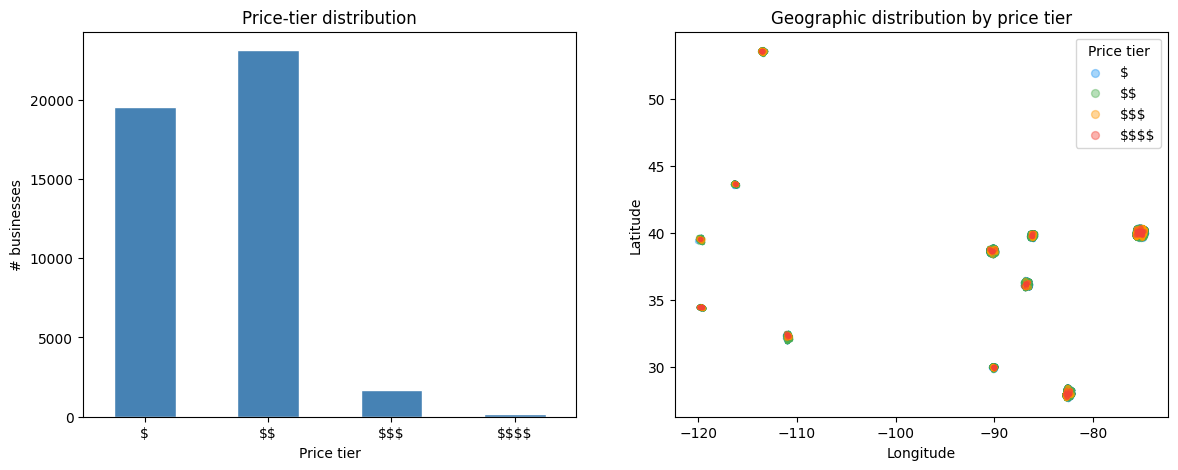

In [ ]:
# Summary stats + charts
from IPython.display import display

print("=== Business summary ===")
print(f"n_businesses : {len(biz_df):,}")
print("\nprice_tier distribution:")
vc = biz_df['price_tier'].value_counts().sort_index()
for t, c in vc.items():
    print(f"  {'$'*t:5s} ({t})  {c:6,}  {c/len(biz_df)*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vc.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Price-tier distribution')
axes[0].set_xlabel('Price tier')
axes[0].set_ylabel('# businesses')
axes[0].set_xticklabels([r'\$', r'\$\$', r'\$\$\$', r'\$\$\$\$'], rotation=0)

colors = {1:'#2196F3', 2:'#4CAF50', 3:'#FF9800', 4:'#F44336'}
for tier in [1, 2, 3, 4]:
    sub = biz_df[biz_df['price_tier'] == tier]
    axes[1].scatter(sub['longitude'], sub['latitude'],
                    c=colors[tier], s=8, alpha=0.4, label=f"{r'\$'*tier}")
axes[1].set_title('Geographic distribution by price tier')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].legend(title='Price tier', markerscale=2)
plt.show()

In [ ]:
X, y = build_feature_table(biz_df, review_df)
print("\nX.head():")
display(X.head())
print("\nX.describe():")
display(X.describe())


--- % missing per column (before imputation) ---
No missing values.

Dropped 13 near-constant columns (>95% one value).

Final X shape : (44484, 36)
  numeric     : 21
  categorical : 15

X.head():


,review_count_log,stars,is_open,latitude,longitude,RestaurantsTakeOut,RestaurantsReservations,RestaurantsDelivery,GoodForKids,OutdoorSeating,...,NoiseLevel_average,NoiseLevel_loud,NoiseLevel_quiet,RestaurantsAttire_casual,rv_count,rv_stars_mean,rv_stars_std,rv_len_chars,rv_len_words,rv_useful_mean
business_id,,,,,,,,,,,,,,,,,,,,,
MTSW4McQd7CbVtyjqoe9mw,4.394449,4.0,1,39.955505,-75.155564,1,0,0,0,0,...,0,0,0,0,38.0,4.105263,1.225616,576.421053,108.131579,2.842105
CF33F8-E6oudUQ46HnavjQ,1.945910,2.0,1,36.269593,-87.058943,1,0,1,1,1,...,0,0,0,1,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
k0hlBqXX-Bt0vf1op7Jr1w,2.995732,3.0,0,38.565165,-90.321087,1,0,0,1,1,...,1,0,0,1,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
bBDDEgkFA1Otx9Lfe7BZUQ,2.397895,1.5,1,36.208102,-86.768170,1,0,1,1,1,...,0,0,0,1,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
il_Ro8jwPlHresjw9EGmBg,3.367296,2.5,1,39.637133,-86.127217,1,0,1,1,0,...,0,0,0,1,0.0,0.000000,0.000000,0.000000,0.000000,0.000000



X.describe():


,review_count_log,stars,is_open,latitude,longitude,RestaurantsTakeOut,RestaurantsReservations,RestaurantsDelivery,GoodForKids,OutdoorSeating,...,NoiseLevel_average,NoiseLevel_loud,NoiseLevel_quiet,RestaurantsAttire_casual,rv_count,rv_stars_mean,rv_stars_std,rv_len_chars,rv_len_words,rv_useful_mean
count,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.00000,44484.000000,...,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000,44484.000000
mean,3.807361,3.464931,0.647851,36.985698,-87.952546,0.906303,0.299861,0.533698,0.75571,0.405089,...,0.540554,0.052761,0.159001,0.846192,3.155359,0.383251,0.140960,70.238743,12.900600,0.250613
std,1.207368,0.808820,0.477646,5.918739,13.878411,0.291409,0.458202,0.498869,0.42967,0.490915,...,0.498358,0.223558,0.365681,0.360769,9.751268,1.115960,0.412661,211.858486,38.821833,0.935923
min,1.791759,1.000000,0.000000,27.564457,-120.083748,0.000000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.833213,3.000000,0.000000,32.221820,-90.242960,1.000000,0.000000,0.000000,1.00000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.737670,3.500000,1.000000,39.480417,-86.069356,1.000000,0.000000,1.000000,1.00000,0.000000,...,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,4.663439,4.000000,1.000000,39.956662,-75.341689,1.000000,1.000000,1.000000,1.00000,1.000000,...,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,8.931816,5.000000,1.000000,53.679197,-74.664459,1.000000,1.000000,1.000000,1.00000,1.000000,...,1.000000,1.000000,1.000000,1.000000,40.000000,5.000000,2.190890,1804.250000,325.541667,31.900000


---
## 3. Train / Val / Test Split


In [ ]:
from sklearn.model_selection import train_test_split

def business_level_split(X, y, seed=42):
    """
    70/15/15 stratified split at the business level.
    X must be indexed by business_id.

    Returns
    -------
    (X_train, y_train), (X_val, y_val), (X_test, y_test)
    """
    ids  = X.index.to_numpy()
    labs = y.loc[ids].to_numpy()

    ids_tv, ids_test, _, _ = train_test_split(
        ids, labs, test_size=0.15, random_state=seed, stratify=labs)

    labs_tv = y.loc[ids_tv].to_numpy()
    val_frac = 0.15 / 0.85
    ids_train, ids_val, _, _ = train_test_split(
        ids_tv, labs_tv, test_size=val_frac, random_state=seed, stratify=labs_tv)

    for split_name, split_ids in [('train', ids_train),
                                   ('val',   ids_val),
                                   ('test',  ids_test)]:
        split_labs = y.loc[split_ids].to_numpy()
        vc  = pd.Series(split_labs).value_counts().sort_index()
        print(f"\n{split_name:5s}  n={len(split_labs):,}")
        for t in [1, 2, 3, 4]:
            c = vc.get(t, 0)
            print(f"  {'$'*t:5s} ({t})  {c:5,}  {c/len(split_labs)*100:.1f}%")

    return (
        (X.loc[ids_train], y.loc[ids_train]),
        (X.loc[ids_val],   y.loc[ids_val]),
        (X.loc[ids_test],  y.loc[ids_test]),
    )

print("business_level_split defined.")

business_level_split defined.


In [ ]:
(X_train, y_train), (X_val, y_val), (X_test, y_test) = business_level_split(X, y)


train  n=31,138
  $     (1)  13,655  43.9%
  $$    (2)  16,183  52.0%
  $$$   (3)  1,164  3.7%
  $$$$  (4)    136  0.4%

val    n=6,673
  $     (1)  2,927  43.9%
  $$    (2)  3,468  52.0%
  $$$   (3)    249  3.7%
  $$$$  (4)     29  0.4%

test   n=6,673
  $     (1)  2,927  43.9%
  $$    (2)  3,468  52.0%
  $$$   (3)    249  3.7%
  $$$$  (4)     29  0.4%


---
## 4. Baseline Model

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def train_baseline(X_train, y_train, X_val, y_val):
    """
    Train a multinomial logistic regression baseline.
    Pipeline: StandardScaler (numeric) + passthrough (binary) + LogisticRegression.
    Evaluates on val and prints classification_report, confusion matrix,
    balanced accuracy, and macro-F1.

    Returns
    -------
    fitted sklearn Pipeline
    """
    binary_cols  = [
        c for c in X_train.columns
        if set(X_train[c].dropna().unique()).issubset({0, 1, 0.0, 1.0})
    ]
    numeric_cols = [c for c in X_train.columns if c not in binary_cols]

    ct = ColumnTransformer([
        ('scale',       StandardScaler(), numeric_cols),
        ('passthrough', 'passthrough',    binary_cols),
    ], remainder='drop')

    pipe = Pipeline([
        ('prep', ct),
        ('lr',   LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            C=1.0,
            solver='lbfgs',
        )),
    ])

    print("Fitting logistic regression pipeline...")
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_val)
    labels = sorted(y_val.unique())

    print("\n=== Validation results ===")
    print(classification_report(
        y_val, y_pred,
        target_names=[f"{'$'*l} ({l})" for l in labels]
    ))

    print("Confusion matrix (rows=true, cols=pred):")
    cm = confusion_matrix(y_val, y_pred, labels=labels)
    cm_df = pd.DataFrame(
        cm,
        index  =[f"true_{'$'*l}"  for l in labels],
        columns=[f"pred_{'$'*l}"  for l in labels],
    )
    print(cm_df.to_string())
    print(f"\nBalanced accuracy : {balanced_accuracy_score(y_val, y_pred):.4f}")
    print(f"Macro F1          : {f1_score(y_val, y_pred, average='macro'):.4f}")

    return pipe


def inspect_coefficients(pipeline, top_k=15):
    """
    Print the top-k positive and top-k negative coefficients for the
    class-4 ($$$$ ) vs class-1 ($) contrast.
    Sanity check: NoiseLevel_quiet, RestaurantsAttire_dressy,
    Alcohol_full_bar should appear as top positive predictors for $$$$.
    """
    lr      = pipeline.named_steps['lr']
    classes = list(lr.classes_)

    if 4 not in classes or 1 not in classes:
        print("Classes 1 and/or 4 not found in model.")
        return

    idx4 = classes.index(4)
    idx1 = classes.index(1)
    contrast = lr.coef_[idx4] - lr.coef_[idx1]

    ct = pipeline.named_steps['prep']
    raw_names   = ct.get_feature_names_out()
    clean_names = [n.split('__', 1)[-1] for n in raw_names]

    coef_s = pd.Series(contrast, index=clean_names)
    print(f"\n=== Top {top_k} positive coefs ($$$$  vs  $) ===")
    print(coef_s.nlargest(top_k).to_string())
    print(f"\n=== Top {top_k} negative coefs ($$$$  vs  $) ===")
    print(coef_s.nsmallest(top_k).to_string())

print("train_baseline and inspect_coefficients defined.")

train_baseline and inspect_coefficients defined.


In [ ]:
pipeline = train_baseline(X_train, y_train, X_val, y_val)

Fitting logistic regression pipeline...

=== Validation results ===
              precision    recall  f1-score   support

       $ (1)       0.71      0.79      0.75      2927
      $$ (2)       0.81      0.54      0.65      3468
     $$$ (3)       0.24      0.63      0.34       249
    $$$$ (4)       0.04      0.55      0.07        29

    accuracy                           0.65      6673
   macro avg       0.45      0.63      0.45      6673
weighted avg       0.74      0.65      0.68      6673

Confusion matrix (rows=true, cols=pred):
           pred_$  pred_$$  pred_$$$  pred_$$$$
true_$       2298      426        42        161
true_$$       931     1880       454        203
true_$$$       10       27       156         56
true_$$$$       2        2         9         16

Balanced accuracy : 0.6264
Macro F1          : 0.4512


In [ ]:
inspect_coefficients(pipeline, top_k=15)


=== Top 15 positive coefs ($$$$  vs  $) ===
rv_len_chars                  6.387953
RestaurantsReservations       2.343417
Alcohol_full_bar              2.165134
GoodForMeal_dinner            1.775377
Alcohol_beer_and_wine         1.565081
Ambience_classy               1.478376
GoodForMeal_breakfast         1.445693
WiFi_no                       0.984353
BusinessAcceptsCreditCards    0.503463
latitude                      0.475447
WiFi_free                     0.367317
is_open                       0.232751
Caters                        0.194229
rv_stars_std                  0.185557
Alcohol_none                  0.127980

=== Top 15 negative coefs ($$$$  vs  $) ===
rv_len_words               -5.640272
Ambience_casual            -2.581733
GoodForMeal_lunch          -2.110808
RestaurantsTakeOut         -1.688505
RestaurantsAttire_casual   -1.361964
GoodForKids                -1.260131
NoiseLevel_loud            -0.909658
rv_stars_mean              -0.655403
BikeParking                -0

---
## 5. Next Steps

1. **TF-IDF on review text** — concatenate review text per business and fit
   `TfidfVectorizer(max_features=5000, ngram_range=(1,2))`; add the sparse
   matrix as an extra branch in the `ColumnTransformer`. Likely the biggest
   single-feature lift.

2. **LightGBM** — replace logistic regression with
   `lightgbm.LGBMClassifier(class_weight='balanced')`. Handles
   non-linearities and feature interactions without scaling; typically
   5-10 pp better macro-F1 than linear models on tabular data.

3. **Photo embeddings via CLIP** — if `yelp_academic_dataset_photo.json`
   and the photo files become available, encode each photo with
   `openai/clip-vit-base-patch32` and mean-pool per business. Visual cues
   (white tablecloths, dim lighting, attire) are strong price-tier signals.
   *(Note: photo file not present in current dataset download.)*

4. **Hyperparameter search** — grid-search `C` ∈ [0.01, 0.1, 1, 10]
   (LR) or `num_leaves` / `learning_rate` (LightGBM) via cross-validation
   on the train split only.

5. **Tip / check-in features** — aggregate tip sentiment and check-in
   frequency from `yelp_academic_dataset_tip.json` and
   `yelp_academic_dataset_checkin.json` as additional business-level signals.

6. **Held-out test evaluation** — run `pipeline.predict(X_test)` only
   after all model selection is complete to get an unbiased estimate.